# Footprint v2: neighborhoods in no-alarm `{y_prob <= 0.02}`

The v1 fingerprint (6 raw categorical columns) left 1,025 of 1,674 frauds alone in thin cells. Footprint v2 is the reduced version: `merchant_tier` (3 tiers from the EDA lift table), `auth_method` (5, the amplifier), `device_type` (8), `is_new_merchant`, and the binarized counters `any_cvv_retry`, `any_prior_dispute`, `any_txn_last_24h`. Out: the time columns, `card_type`, `channel` (established by the earlier audits). Theoretical space 3 x 5 x 8 x 2 x 2 x 2 x 2 = 1,920 cells on 590k rows.

Two cells, two questions. **Census:** how many cells exist and how much occupancy is behind them; does every footprint column still earn its place inside the region. **Neighborhoods:** for each cell, occupancy, fraud count, rate, enrichment vs the 0.28% background; and how the 1,674 frauds distribute over cells.

Pre-registered candidate rule (fixed before running): a cell is a *candidate missed pattern* when it holds >= 5 frauds, enrichment >= 2, and the Wilson 95% lower bound of its rate is above the region rate. The rank cross-check (better- vs worse-ranked fraud halves) says whether the model already uses the enrichment or leaves it on the table.


In [1]:
import importlib
import sys
from ccf_ml import file_utils
from ccf_ml.cross_validation import alarm as alarm_mod
importlib.reload(file_utils)
importlib.reload(alarm_mod)

from ccf_ml.cross_validation.alarm import alarm_flag_mask
from ccf_ml.cross_validation.constants import (
    ALARM_FLAG_COLUMNS,
    ID_COLUMN,
    TARGET_COLUMN,
)
from ccf_ml.file_utils import (
    get_repo_root,
    get_script_plot_dir,
    get_script_table_dir,
    get_train_csv_path,
    get_training_oof_path,
)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DELIMITER_VALUE = "-" * 50
NOTEBOOK_STEM = "footprint_v2"
EXP_NAME = "hgb_baseline"
PROB_COL = "y_prob"
FOLD_COL = "fold_id"
SCORE_CUT = 0.02
MERCHANT_COL = "merchant_category"
AUTH_COL = "auth_method"
DEVICE_COL = "device_type"
NEW_MERCHANT_COL = "is_new_merchant"
CVV_COL = "cvv_retry_count"
DISPUTE_COL = "prior_disputes"
TXN24_COL = "txn_count_last_24h"
MERCHANT_TIERS = {
    "hot": ("Gift Cards", "Crypto Exchange", "Gaming"),
    "warm": ("Electronics", "Streaming"),
    "background": (
        "Travel",
        "Utilities",
        "Healthcare",
        "Fuel",
        "Restaurants",
        "Groceries",
        "Online Retail",
    ),
}
TIER_BY_MERCHANT = {
    merchant: tier
    for tier, merchants in MERCHANT_TIERS.items()
    for merchant in merchants
}
tables_dir = get_script_table_dir(NOTEBOOK_STEM)

train_df = pd.read_csv(get_train_csv_path())
oof_df = pd.read_csv(get_training_oof_path(EXP_NAME))
train_features = train_df.drop(columns=[TARGET_COLUMN])
frame = train_features.merge(oof_df, on=ID_COLUMN, how="inner", validate="one_to_one")
if len(frame) != len(train_df) or len(frame) != len(oof_df):
    raise ValueError(
        f"join lost rows: train={len(train_df)} oof={len(oof_df)} joined={len(frame)}"
    )
has_alarm = alarm_flag_mask(frame, columns=ALARM_FLAG_COLUMNS)
region = frame.loc[(~has_alarm) & (frame[PROB_COL] <= SCORE_CUT)].copy()
region["merchant_tier"] = region[MERCHANT_COL].map(TIER_BY_MERCHANT)
if region["merchant_tier"].isna().any():
    raise ValueError("unmapped merchant category inside the region")
region["any_cvv_retry"] = region[CVV_COL] > 0
region["any_prior_dispute"] = region[DISPUTE_COL] > 0
region["any_txn_last_24h"] = region[TXN24_COL] > 0
FP_COLUMNS = (
    "merchant_tier",
    AUTH_COL,
    DEVICE_COL,
    NEW_MERCHANT_COL,
    "any_cvv_retry",
    "any_prior_dispute",
    "any_txn_last_24h",
)
n_region = len(region)
n_fraud_region = int((region[TARGET_COLUMN] == 1).sum())
rate_region = n_fraud_region / n_region
print("n_region", n_region)
print("n_fraud_region", n_fraud_region)
print("rate_region", round(rate_region, 6))
print("footprint columns", list(FP_COLUMNS))
for _col in FP_COLUMNS:
    print(_col, "levels:", int(region[_col].nunique()))


P(is_fraud | merchant_tier) inside the region (base rate 0.0028)
                    n  n_fraud    rate    lift  rate_lo  rate_hi
merchant_tier                                                   
background     489858     1220  0.0025  0.8779   0.0024   0.0026
hot             24412      146  0.0060  2.1081   0.0050   0.0069
warm            75800      308  0.0041  1.4323   0.0036   0.0045
--------------------------------------------------
P(is_fraud | auth_method) inside the region (base rate 0.0028)
                        n  n_fraud    rate    lift  rate_lo  rate_hi
auth_method                                                         
3D Secure          177697      526  0.0030  1.0434   0.0027   0.0032
Biometric           84803      140  0.0017  0.5819   0.0014   0.0019
No Authentication   42698      273  0.0064  2.2537   0.0056   0.0071
OTP                149087      408  0.0027  0.9646   0.0025   0.0030
PIN                135785      327  0.0024  0.8489   0.0021   0.0027
-------------

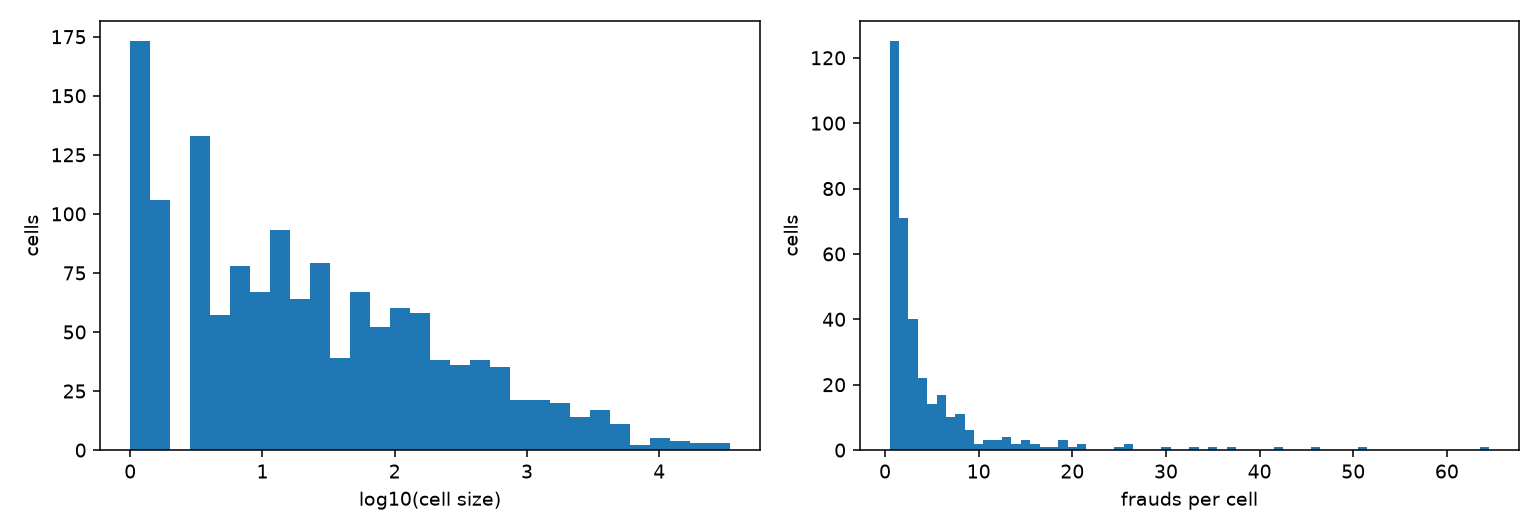

In [2]:
level_parts: dict[str, pd.DataFrame] = {}
for col in FP_COLUMNS:
    grouped = region.groupby(col, observed=True)[TARGET_COLUMN].agg(["size", "sum"])
    grouped.columns = ["n", "n_fraud"]
    grouped["rate"] = grouped["n_fraud"] / grouped["n"]
    grouped["lift"] = grouped["rate"] / rate_region
    se = np.sqrt(grouped["rate"] * (1.0 - grouped["rate"]) / grouped["n"])
    grouped["rate_lo"] = np.maximum(grouped["rate"] - 1.96 * se, 0.0)
    grouped["rate_hi"] = grouped["rate"] + 1.96 * se
    print(f"P(is_fraud | {col}) inside the region (base rate {rate_region:.4f})")
    print(grouped.round(4).to_string())
    print(DELIMITER_VALUE)
    grouped = grouped.reset_index()
    grouped.insert(0, "column", col)
    level_parts[col] = grouped
level_table = pd.concat(level_parts.values(), ignore_index=True)
level_path = tables_dir / "fp2_column_level_table.csv"
level_table.to_csv(level_path, index=False)
print("saved", level_path)
print(DELIMITER_VALUE)

theoretical_total = 1
for col in FP_COLUMNS:
    theoretical_total *= int(region[col].nunique())
codes = region.loc[:, list(FP_COLUMNS)].copy()
for col in FP_COLUMNS:
    codes[col], _ = pd.factorize(codes[col])
n_observed = len(codes.drop_duplicates(ignore_index=True))
cell_sizes = codes.groupby(list(FP_COLUMNS)).size()
fraud_codes = codes.loc[region[TARGET_COLUMN] == 1]
n_fraud_observed = len(fraud_codes.drop_duplicates(ignore_index=True))
frauds_per_cell = cell_sizes  # placeholder to keep names straight
cell_fraud_counts = (
    codes.loc[region[TARGET_COLUMN] == 1].groupby(list(FP_COLUMNS)).size()
)
census_row: dict[str, object] = {
    "n_columns": len(FP_COLUMNS),
    "theoretical_total": theoretical_total,
    "n_observed_cells": n_observed,
    "density": n_observed / theoretical_total,
    "median_cell_size": float(cell_sizes.median()),
    "mean_cell_size": float(cell_sizes.mean()),
    "p90_cell_size": float(cell_sizes.quantile(0.9)),
    "share_cells_ge_100": float((cell_sizes >= 100).mean()),
    "share_cells_ge_300": float((cell_sizes >= 300).mean()),
    "share_rows_in_cells_ge_100": float((cell_sizes[cell_sizes >= 100]).sum() / n_region),
    "n_cells_with_fraud": int((cell_fraud_counts > 0).sum()),
    "n_fraud_observed_cells": n_fraud_observed,
    "median_frauds_per_fraud_cell": float(cell_fraud_counts[cell_fraud_counts > 0].median()),
}
census_table = pd.DataFrame([census_row])
print(census_table.transpose().to_string())
census_path = tables_dir / "fp2_census.csv"
census_table.to_csv(census_path, index=False)
print("saved", census_path)
print(DELIMITER_VALUE)
print("cell size percentiles")
print(cell_sizes.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).round(1).to_string())
print(DELIMITER_VALUE)
print("frauds per cell (cells containing at least one fraud)")
print(
    cell_fraud_counts[cell_fraud_counts > 0]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99])
    .round(3)
    .to_string()
)

plot_dir = get_script_plot_dir(NOTEBOOK_STEM, section="census")
fig, axes = plt.subplots(1, 2, figsize=(11.0, 3.8))
axes[0].hist(np.log10(cell_sizes.to_numpy(dtype=np.float64)), bins=30)
axes[0].set_xlabel("log10(cell size)")
axes[0].set_ylabel("cells")
fpc = cell_fraud_counts[cell_fraud_counts > 0]
axes[1].hist(fpc.to_numpy(dtype=np.float64), bins=np.arange(0.5, fpc.max() + 1.5, 1.0))
axes[1].set_xlabel("frauds per cell")
axes[1].set_ylabel("cells")
fig.tight_layout()
census_plot = plot_dir / "fp2_census.png"
fig.savefig(census_plot, dpi=140)
print("saved", census_plot)


candidate missed-pattern cells (n_fraud >= 5, enrichment >= 2.0, Wilson 95% lower bound > region rate): 38
--------------------------------------------------
cells with the most fraud
merchant_tier       auth_method   device_type  is_new_merchant  any_cvv_retry  any_prior_dispute  any_txn_last_24h  n_cell  n_fraud_cell  rate_cell  enrichment  candidate
   background         3D Secure Android Phone            False          False              False              True   33993            64   0.001883    0.663649      False
   background               OTP Android Phone            False          False              False              True   28812            51   0.001770    0.623943      False
   background         3D Secure        iPhone            False          False              False              True   23369            46   0.001968    0.693850      False
   background No Authentication Android Phone            False          False              False              True    9372          

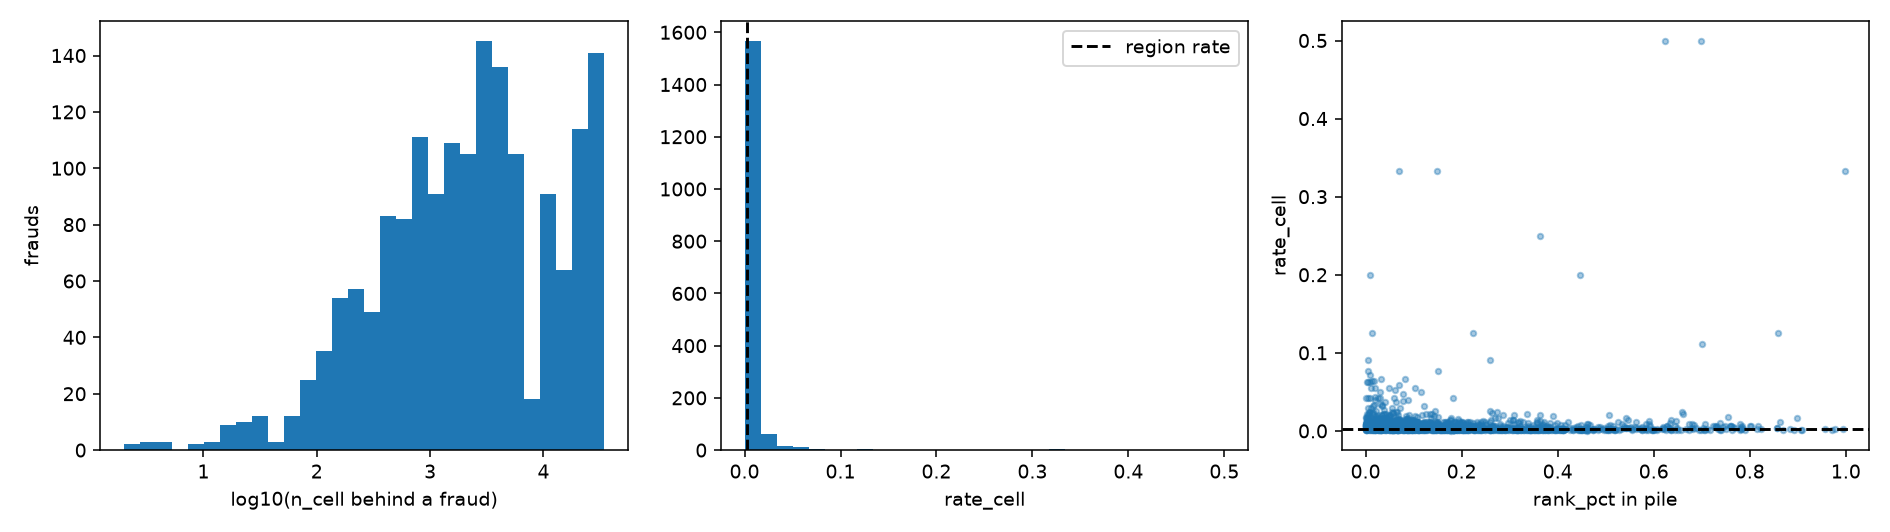

In [3]:
cell_stats = (
    region.groupby(list(FP_COLUMNS), observed=True)[TARGET_COLUMN]
    .agg(n_cell="size", n_fraud_cell="sum")
    .reset_index()
)
cell_stats["rate_cell"] = cell_stats["n_fraud_cell"] / cell_stats["n_cell"]
cell_stats["enrichment"] = cell_stats["rate_cell"] / rate_region
z = 1.96
p_hat = cell_stats["rate_cell"].to_numpy(dtype=np.float64)
n_arr = cell_stats["n_cell"].to_numpy(dtype=np.float64)
center = (p_hat + z * z / (2.0 * n_arr)) / (1.0 + z * z / n_arr)
half = (
    z
    * np.sqrt(p_hat * (1.0 - p_hat) / n_arr + z * z / (4.0 * n_arr * n_arr))
    / (1.0 + z * z / n_arr)
)
cell_stats["wilson_lo"] = center - half
MIN_FRAUD_CELL = 5
MIN_ENRICHMENT = 2.0
cell_stats["candidate"] = (
    (cell_stats["n_fraud_cell"] >= MIN_FRAUD_CELL)
    & (cell_stats["enrichment"] >= MIN_ENRICHMENT)
    & (cell_stats["wilson_lo"] > rate_region)
)
n_candidates = int(cell_stats["candidate"].sum())
print(f"candidate missed-pattern cells (n_fraud >= {MIN_FRAUD_CELL}, "
      f"enrichment >= {MIN_ENRICHMENT}, Wilson 95% lower bound > region rate): {n_candidates}")
print(DELIMITER_VALUE)
print("cells with the most fraud")
print(
    cell_stats.sort_values("n_fraud_cell", ascending=False)
    .head(10)[list(FP_COLUMNS) + ["n_cell", "n_fraud_cell", "rate_cell", "enrichment", "candidate"]]
    .to_string(index=False)
)
print(DELIMITER_VALUE)
big = cell_stats.loc[cell_stats["n_cell"] >= 100]
print("highest-rate cells among n_cell >= 100")
print(
    big.sort_values("rate_cell", ascending=False)
    .head(10)[list(FP_COLUMNS) + ["n_cell", "n_fraud_cell", "rate_cell", "enrichment", "candidate"]]
    .to_string(index=False)
)
print(DELIMITER_VALUE)
if n_candidates:
    print("all candidate cells")
    print(
        cell_stats.loc[cell_stats["candidate"]]
        .sort_values("n_fraud_cell", ascending=False)
        [list(FP_COLUMNS) + ["n_cell", "n_fraud_cell", "rate_cell", "enrichment"]]
        .to_string(index=False)
    )
cell_stats_path = tables_dir / "fp2_cell_stats.csv"
cell_stats.to_csv(cell_stats_path, index=False)
print("saved", cell_stats_path)
print(DELIMITER_VALUE)

fraud_profile = region.loc[region[TARGET_COLUMN] == 1].merge(
    cell_stats,
    on=list(FP_COLUMNS),
    how="left",
    validate="many_to_one",
)
if fraud_profile["n_cell"].isna().any():
    raise ValueError("some frauds did not match a footprint cell")
n_singleton_fraud_cells = int((fraud_profile["n_fraud_cell"] == 1).sum())
print("fraud-side view (v1 numbers in parentheses: 1,305 fingerprints, 1,025 alone, median cell 113, 28 unique)")
print("frauds whose cell holds no other fraud:", n_singleton_fraud_cells, "(v1: 1,025)")
print("frauds in cells with >= 2 frauds:", int((fraud_profile["n_fraud_cell"] >= 2).sum()))
print("median cell size behind a fraud:", float(fraud_profile["n_cell"].median()), "(v1: 113)")
print("median rate_cell:", round(float(fraud_profile["rate_cell"].median()), 5))
print("mean rate_cell:", round(float(fraud_profile["rate_cell"].mean()), 5))
print("median enrichment:", round(float(fraud_profile["enrichment"].median()), 3))
print("frauds in candidate cells:", int(fraud_profile["n_fraud_cell"].where(fraud_profile["candidate"]).notna().sum()))
print(DELIMITER_VALUE)
enrich_dist = (
    fraud_profile["enrichment"]
    .describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99])
    .round(3)
)
print("enrichment distribution over the 1,674 frauds")
print(enrich_dist.to_string())

ranks_path = get_script_table_dir("oof_alarm_region_auc") / "no_alarm_p_le_0p02_fraud_ranks.csv"
ranks = pd.read_csv(ranks_path)
fraud_profile = fraud_profile.merge(
    ranks[[ID_COLUMN, "rank", "rank_pct"]],
    on=ID_COLUMN,
    how="left",
    validate="one_to_one",
)
if fraud_profile["rank"].isna().any():
    raise ValueError("some frauds are missing ranks")
median_rank = fraud_profile["rank"].median()
better = fraud_profile.loc[fraud_profile["rank"] < median_rank]
worse = fraud_profile.loc[fraud_profile["rank"] >= median_rank]
print(DELIMITER_VALUE)
print("better-ranked half: median rate_cell", round(float(better["rate_cell"].median()), 5),
      "mean", round(float(better["rate_cell"].mean()), 5))
print("worse-ranked half: median rate_cell", round(float(worse["rate_cell"].median()), 5),
      "mean", round(float(worse["rate_cell"].mean()), 5))
fraud_profile_path = tables_dir / "fp2_fraud_profile.csv"
keep = [ID_COLUMN, FOLD_COL, PROB_COL, "rank", "rank_pct"] + list(FP_COLUMNS) + [
    "n_cell",
    "n_fraud_cell",
    "rate_cell",
    "enrichment",
    "wilson_lo",
    "candidate",
]
fraud_profile.loc[:, keep].to_csv(fraud_profile_path, index=False)
print("saved", fraud_profile_path)

plot_dir = get_script_plot_dir(NOTEBOOK_STEM, section="neighborhoods")
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))
axes[0].hist(np.log10(fraud_profile["n_cell"].to_numpy(dtype=np.float64)), bins=30)
axes[0].set_xlabel("log10(n_cell behind a fraud)")
axes[0].set_ylabel("frauds")
axes[1].hist(fraud_profile["rate_cell"].to_numpy(dtype=np.float64), bins=30)
axes[1].axvline(rate_region, color="black", linestyle="--", label="region rate")
axes[1].set_xlabel("rate_cell")
axes[1].legend()
axes[2].scatter(
    fraud_profile["rank_pct"].to_numpy(dtype=np.float64),
    fraud_profile["rate_cell"].to_numpy(dtype=np.float64),
    s=8,
    alpha=0.4,
)
axes[2].axhline(rate_region, color="black", linestyle="--")
axes[2].set_xlabel("rank_pct in pile")
axes[2].set_ylabel("rate_cell")
fig.tight_layout()
neighborhoods_plot = plot_dir / "fp2_neighborhoods.png"
fig.savefig(neighborhoods_plot, dpi=140)
print("saved", neighborhoods_plot)


## Takeaway: footprint v2

1. **The reduction did its job.** Median cell behind a fraud: 113 -> 2,474 rows. Frauds alone in their cell: 1,025 -> 125. 1,549 of 1,674 frauds now share a cell with at least one other fraud. Cells finally have real local contrast.

2. **Every column earns its keep except `device_type`.** Inside the region: hot tier 2.1x, No Authentication 2.25x, new merchant 1.88x, `any_cvv_retry` 2.62x (strongest single column), `txn_count_last_24h = 0` is a 0.17x shield (8 frauds in 16.8k rows). `device_type` is flat (lifts 0.88-1.15, intervals straddle 1) - it splits cells without adding signal, the first candidate to drop in a v3.

3. **38 cells pass the pre-registered candidate rule, holding 391 frauds (23% of the pile).** They read as clean rules: No Authentication on iPhone / POS Terminal / Android (2.1-2.4x at scale), OTP or PIN combined with `any_cvv_retry` (3.9-4.0x), 3D Secure with new merchant (2.9-3.1x). Hottest single cell: background x No Authentication x Android Phone x new merchant x prior dispute - 6 frauds in 143 rows (4.2%, 14.8x).

4. **The rank cross-check tempers the celebration.** Better-ranked frauds live in hotter cells (median rate 0.59%) while the buried half sits exactly at background (0.29% vs region 0.28%). The model already ranks the enriched footprints higher; the frauds it misses are *not* concentrated in categorical cells.

5. **Next step:** inside the 38 candidate cells, compare the model's mean OOF score with the observed cell rate. Score below rate -> the model under-uses a verified hot cell -> explicit interaction features (tier x auth x cvv_retry). Score matching rate -> the cells are captured and the leftover error lives elsewhere (numerics or noise).
